# Questions 1.1 to 1.6

### Imports

In [1]:
import config as cfg
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import src.loading as ld
from src.plotting import draw_landmarks, overlay_video

## Q1.1

In [2]:
full_df = ld.load_frames(include_tests=True) # force=True to remake the parquet file | include_tests=True to include test actors

full_df

,video_id,actor,sex,emotion,intensity,statement,repetition,is_test,frame,timestamp,...,y_58,y_59,y_60,y_61,y_62,y_63,y_64,y_65,y_66,y_67
0,01-01-01-01-01-01-01,1,M,1,1,1,1,1,1,0.000,...,468.2,460.1,443.7,446.2,448.9,448.1,450.5,448.5,449.4,447.2
1,01-01-01-01-01-01-01,1,M,1,1,1,1,1,2,0.033,...,467.4,459.1,442.4,444.8,447.5,446.7,449.7,448.1,448.9,446.5
2,01-01-01-01-01-01-01,1,M,1,1,1,1,1,3,0.067,...,467.0,458.5,441.9,444.3,447.1,446.4,449.7,448.3,449.0,446.4
3,01-01-01-01-01-01-01,1,M,1,1,1,1,1,4,0.100,...,466.9,458.6,442.1,444.3,447.1,446.3,450.0,448.5,449.2,446.6
4,01-01-01-01-01-01-01,1,M,1,1,1,1,1,5,0.133,...,467.1,458.8,442.6,444.8,447.5,446.8,450.4,449.0,449.7,447.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159217,01-01-08-02-02-02-24,24,F,8,2,2,2,1,105,3.470,...,539.0,526.4,494.7,496.2,496.9,491.4,482.1,512.3,517.7,516.8
159218,01-01-08-02-02-02-24,24,F,8,2,2,2,1,106,3.504,...,540.3,527.4,495.2,497.5,498.4,493.2,484.4,514.3,519.4,518.2
159219,01-01-08-02-02-02-24,24,F,8,2,2,2,1,107,3.537,...,542.2,529.1,496.5,499.3,500.3,495.3,486.5,516.5,521.5,520.2
159220,01-01-08-02-02-02-24,24,F,8,2,2,2,1,108,3.570,...,544.7,531.7,499.7,502.1,503.1,497.9,488.9,518.9,524.1,522.8


As expected, there are 147 columns in the dataset, which are: **video_id**, **actor**, **sex**, **emotion**, **intensity**, **statement**, **repetition**, **is_test**, **frame**, **timestamp**, **confidence** and the coordinates **x** and **y** of the 68 landmarks.\
The number of rows depends on the number of frames in each video, including test actors there are 159222, and excluding test actors there are 132176 rows.\
Test rows are those with **is_test** equal to 1.

## Q1.2

In [3]:
df = ld.load_frames()

videos_df = ld.video_table(df)
videos_df["emotion_name"] = videos_df["emotion"].map(cfg.EMOTIONS)

videos_df

,video_id,actor,sex,emotion,intensity,statement,repetition,n_frames,emotion_name
0,01-01-01-01-01-01-02,2,F,1,1,1,1,109,neutral
1,01-01-01-01-01-01-03,3,M,1,1,1,1,103,neutral
2,01-01-01-01-01-01-04,4,F,1,1,1,1,99,neutral
3,01-01-01-01-01-01-05,5,M,1,1,1,1,108,neutral
4,01-01-01-01-01-01-06,6,F,1,1,1,1,99,neutral
...,...,...,...,...,...,...,...,...,...
1195,01-01-08-02-02-02-19,19,M,8,2,2,2,97,surprised
1196,01-01-08-02-02-02-20,20,F,8,2,2,2,103,surprised
1197,01-01-08-02-02-02-21,21,M,8,2,2,2,106,surprised
1198,01-01-08-02-02-02-22,22,F,8,2,2,2,109,surprised


Number of rows is 1200 since we are only considering development actors.

In [4]:
videos_df["intensity_name"] = videos_df["intensity"].map({1: "normal", 2: "strong"})
pd.crosstab(videos_df["emotion_name"], videos_df["intensity_name"], margins=True)

intensity_name,normal,strong,All
emotion_name,,,
angry,80,80,160
calm,80,80,160
disgust,80,80,160
fearful,80,80,160
happy,80,80,160
neutral,80,0,80
sad,80,80,160
surprised,80,80,160
All,640,560,1200


160 videos per emotion, of course only 80 for neutral, having in total 640 normal and 560 strong. Therefore, the use of F1 score is justified, since the dataset is unbalanced.

In [5]:
order = list(cfg.EMOTIONS.values())
videos_df.groupby("emotion_name")["n_frames"].describe().reindex(order)

,count,mean,std,min,25%,50%,75%,max
emotion_name,,,,,,,,
neutral,80.0,104.33750,6.314427,92.0,99.0,105.0,108.00,119.0
calm,160.0,113.56875,10.603561,88.0,107.0,112.0,120.00,143.0
happy,160.0,108.30625,8.083679,93.0,103.0,107.0,113.00,132.0
sad,160.0,109.95625,8.676830,93.0,104.0,109.0,114.25,142.0
angry,160.0,115.28125,9.355436,97.0,108.0,114.0,122.00,143.0
fearful,160.0,105.56875,8.225304,92.0,99.0,105.0,110.25,131.0
disgust,160.0,117.13750,11.505256,94.0,110.0,116.0,123.00,157.0
surprised,160.0,104.11250,7.556069,89.0,98.0,104.5,109.00,138.0


The mean differs between emotions: disgust, angry and calm are the longest, and surprised, neutral and fearful the shortest. Neutral also has the smallest standard deviation (6.3 frames) 

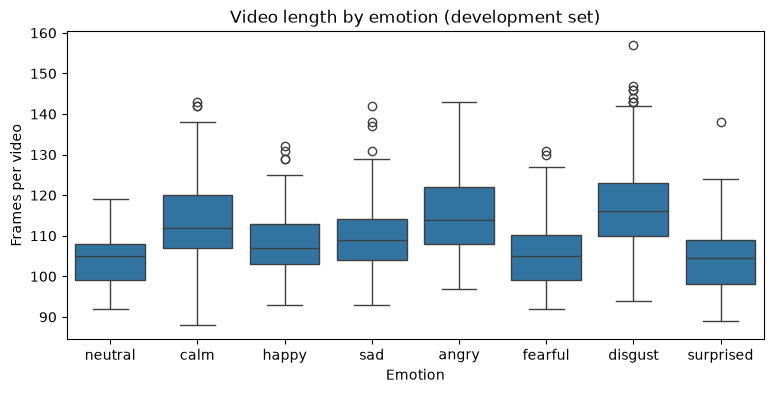

In [6]:
order = list(cfg.EMOTIONS.values())

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=videos_df, x="emotion_name", y="n_frames", order=order, ax=ax)
ax.set_xlabel("Emotion")
ax.set_ylabel("Frames per video")
ax.set_title("Video length by emotion (development set)")
plt.show()

Disgust, Angry and Calm have the most frames, while surprised, neutral and fearful have the least, happy and sad are in between.

## Q1.3

In [7]:
frames_per_video = videos_df["n_frames"].describe()
videos_per_actor = videos_df.groupby("actor").size()

print(f"Frames per video: min {frames_per_video['min']:.0f}, median {frames_per_video['50%']:.0f}, max {frames_per_video['max']:.0f}")
print(f"Development actors: {videos_per_actor.size}, videos per actor: {sorted(videos_per_actor.unique().tolist())}")

Frames per video: min 88, median 109, max 157
Development actors: 20, videos per actor: [60]


One row of the frame table (1.1) is one frame of one video: the positions of the 68 landmarks at a single instant (1/30 s), together with the identifiers of the video it belongs to. One row of the video table (1.2) is one video: one actor portraying one emotion, at one intensity, saying one statement, in one repetition. A video summarises between 88 and 157 frames.

The column that identifies groups of rows that are not independent is actor. Each of the 20 development actors contributes 60 videos, and these 60 videos share things that have nothing to do with the emotion: the geometry of one face (mouth width, eye and brow spacing, jaw shape), the same way of acting each emotion, and the same position in front of the camera. Because of this, knowing one video of an actor already tells us something about that actor's other videos, beyond what the emotion tells us. The same holds at the frame level, where consecutive frames of one video are almost identical; since every frame belongs to a video of one actor, grouping by actor covers both levels.

## Q1.4

In [8]:
per_actor = videos_df.pivot_table(index="actor", columns="emotion_name", values="n_frames", aggfunc="mean")
n_actors = len(per_actor)

print(f"Actors with disgust longer than surprised: {(per_actor['disgust'] > per_actor['surprised']).sum()} of {n_actors}")
print(f"Actors with angry longer than neutral: {(per_actor['angry'] > per_actor['neutral']).sum()} of {n_actors}")

Actors with disgust longer than surprised: 20 of 20
Actors with angry longer than neutral: 19 of 20


The duration of a video is related to the emotion. The box plot of 1.2 shows that disgust, angry and calm videos are the longest, and surprised, neutral and fearful the shortest. The relation is not an effect of who recorded the videos: comparing within each actor, disgust is longer than surprised for all 20 actors, and angry is longer than neutral for 19 of them. A likely cause is speech: the actors say a sentence, and angry or disgusted speech tends to be slower and more emphatic.

Its use as a feature would not be legitimate. The length of a clip in this dataset comes from how the recordings were made and cut around a spoken sentence, not from the face. In an application, the length of a new recording is set by the user and the recording interface (the provided app records clips of 3 to 5 s), so the same number would mean something different, and a model relying on it would have learned a shortcut of the dataset rather than the expression.

## Q1.5

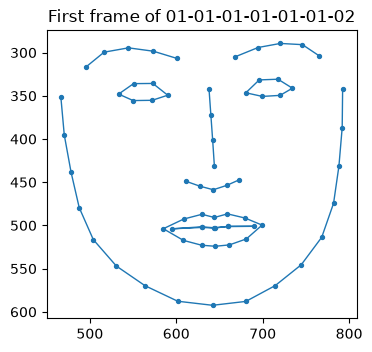

In [9]:
actor, statement, repetition = 2, 1, 1
same_take = (videos_df["actor"] == actor) & (videos_df["statement"] == statement) & (videos_df["repetition"] == repetition)

neutral_id = videos_df.loc[same_take & (videos_df["emotion"] == 1), "video_id"].item()
surprised_id = videos_df.loc[same_take & (videos_df["emotion"] == 8) & (videos_df["intensity"] == 2), "video_id"].item()

ax = draw_landmarks(df[df["video_id"] == neutral_id].iloc[0])
ax.set_title(f"First frame of {neutral_id}")
plt.show()

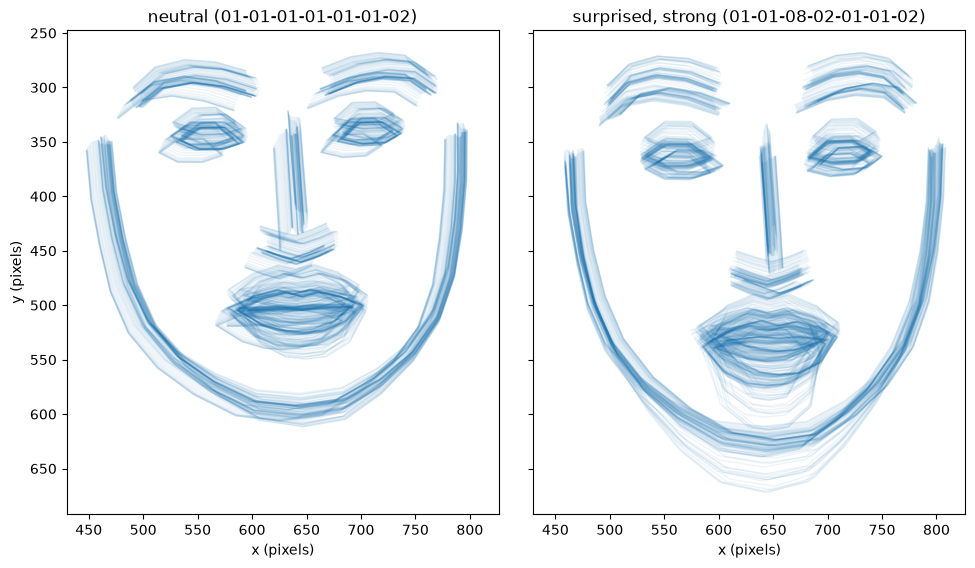

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.5), sharex=True, sharey=True)

for ax, video_id, name in zip(axes, [neutral_id, surprised_id], ["neutral", "surprised, strong"]):
    overlay_video(df[df["video_id"] == video_id], ax=ax)
    ax.set_title(f"{name} ({video_id})")
    ax.set_xlabel("x (pixels)")
axes[0].set_ylabel("y (pixels)")

plt.tight_layout()
plt.show()

The two overlays show actor 2 saying statement 1, in the neutral expression and in surprise at strong intensity. In the surprised video the jaw drops and the mouth opens: the chin reaches about 670 px, against about 610 px in the neutral video, and the inner lips separate much more. The brows rise away from the eyes, so the gap between brows and eyes is larger than in the neutral video. In the neutral video the shape of the face changes little, and most of the spread is the mouth moving while speaking.

The overlays also show movement that is not expression. In both videos the eyes, the brows and the nose appear as stacked copies, because the whole head moves while the actor speaks, and the surprised face sits lower in the image than the neutral one. The position of the head and the expression are mixed.

## Q1.6

In [11]:
# Number and percentage of frames for each confidence value
confidence_counts = df["confidence"].value_counts().sort_index(ascending=False)
pd.DataFrame({"frames": confidence_counts, "percent": (100 * confidence_counts / len(df)).round(2)})

,frames,percent
confidence,,
0.98,130484,98.72
0.93,1578,1.19
0.88,98,0.07
0.82,10,0.01
0.77,6,0.00


In [12]:
# Share of frames below the top confidence (0.98), per emotion and intensity
low_confidence = df["confidence"] < 0.98 #mask t/f
low_share = 100 * low_confidence.groupby([df["emotion"].map(cfg.EMOTIONS), df["intensity"]]).mean()

low_share.unstack().reindex(list(cfg.EMOTIONS.values())).rename(columns={1: "normal", 2: "strong"}).round(1)

intensity,normal,strong
emotion,,
neutral,0.1,NaN
calm,0.3,1.0
happy,0.2,1.8
sad,0.5,0.2
angry,0.8,4.3
fearful,0.3,2.6
disgust,1.6,2.6
surprised,0.9,1.5


In [13]:
# Frames with the lowest confidence and the videos they belong to
df.loc[df["confidence"] == df["confidence"].min(), ["video_id", "actor", "frame", "confidence"]]

,video_id,actor,frame,confidence
35350,01-01-03-02-01-01-06,6,32,0.77
73598,01-01-05-02-01-02-09,9,30,0.77
75884,01-01-05-02-02-01-08,8,32,0.77
76144,01-01-05-02-02-01-10,10,54,0.77
88846,01-01-06-02-01-01-08,8,26,0.77
89906,01-01-06-02-01-01-20,20,33,0.77


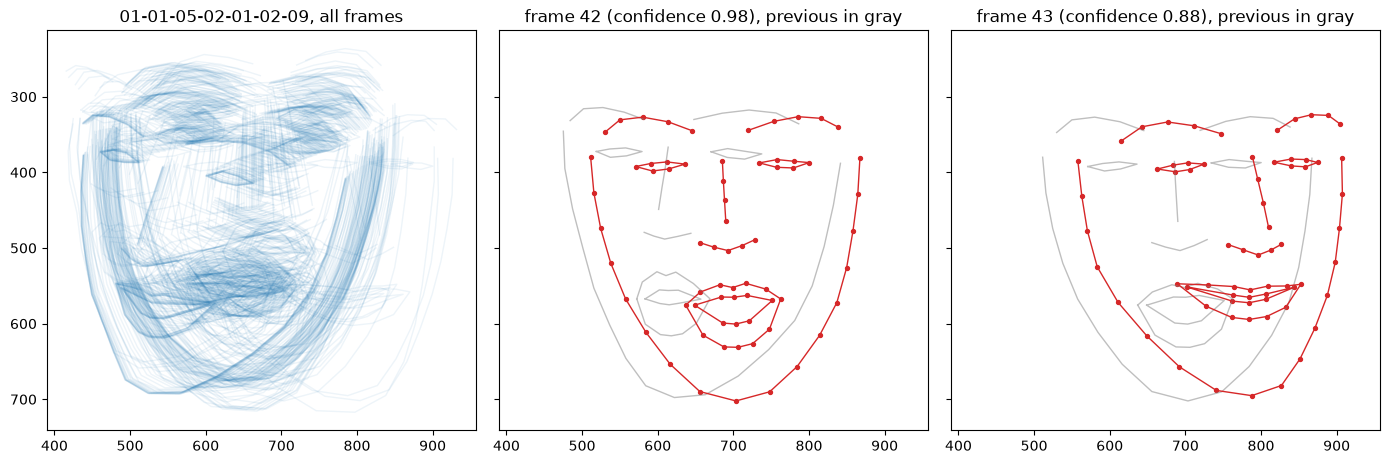

In [14]:
# Example: one of the videos with the lowest confidence (actor 9, angry, strong)
example_id = "01-01-05-02-01-02-09"
example = df[df["video_id"] == example_id].set_index("frame")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True)

# Left: all the frames of the video overlaid
overlay_video(example, ax=axes[0])
axes[0].set_title(f"{example_id}, all frames")

# Middle and right: one frame in red over the previous one in gray
for ax, frame in zip(axes[1:], [42, 43]):
    draw_landmarks(example.loc[frame - 1], ax=ax, color="gray", alpha=0.5, points=False)
    draw_landmarks(example.loc[frame], ax=ax, color="tab:red")
    ax.set_title(f"frame {frame} (confidence {example.loc[frame, 'confidence']}), previous in gray")

plt.tight_layout()
plt.show()

The confidence takes only five values, and 98.7 % of the development frames have the highest, 0.98. The lowest value is 0.77, found in six frames of six different videos, and no frame is close to 0, so the tracker never lost the face completely. The lower values are most frequent at strong intensity, in particular in angry videos (4.3 % of the frames, against 0.1 % in neutral). In these videos the tracking can fail partially: in one of the six videos with the lowest confidence (actor 9, angry, strong), the face shifts far to the side from one frame to the next, and in frame 43 (confidence 0.88) the mouth collapses into a weird shape.

For section 2, there are no frames to discard because the face was lost, but a few frames carry wrong coordinates and will appear among the outliers of 2.2; the confidence can help to decide in 2.3 whether a flagged frame is a tracker error or an extreme expression. These frames cannot simply be removed, because they are concentrated in the strongest expressions, and removing them would take away mostly frames of those emotions.